# EDA 01 — Consumo CMV | Fenix GastroCore

**Objetivo:** explorar o conjunto Silver de consumo de CMV, validar indicadores, descrever distribuições, investigar relações e registrar limitações.

**Fonte:** `gastrocore_consumo_cmv_silver.csv` (20 registros, 17 colunas).  
**Política:** análise não altera o arquivo de origem; achados são exploratórios e não substituem homologação das regras de negócio pelo CESIC.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ARQUIVO = Path("gastrocore_consumo_cmv_silver.csv")
df = pd.read_csv(ARQUIVO)
df["data_competencia"] = pd.to_datetime(df["data_competencia"], errors="coerce")
display(df.head())
print("Dimensões:", df.shape)

,id_consumo,data_competencia,id_filial,nome_filial,categoria_insumo,nome_insumo,qtd_prevista_kg,qtd_real_kg,custo_unitario_kg,cmv_orcado_reais,cmv_realizado_reais,desvio_cmv_reais,desvio_cmv_percentual,classificacao_abc,fator_correcao_teorico,fator_correcao_real,motivo_desvio
0,1,2026-03-01,1,Cozinha Central Recife Antigo,Proteina Bovina,Acem Bovina em Cubos,340.0,378.5,34.5,11730.0,13058.25,1328.25,11.32,Curva A,1.25,1.39,Lote com teor de gordura e aponeurose superior...
1,2,2026-03-01,1,Cozinha Central Recife Antigo,Proteina Ave,Peito de Frango Sem Osso,420.0,432.0,19.8,8316.0,8553.60,237.60,2.86,Curva A,1.10,1.13,Variacao dentro da margem de tolerancia operac...
2,3,2026-03-01,1,Cozinha Central Recife Antigo,Graos e Cereais,Arroz Parboilizado Tipo 1,180.0,185.0,6.2,1116.0,1147.00,31.00,2.78,Curva B,1.00,1.02,Rendimento estavel no cozimento a vapor
3,4,2026-03-01,1,Cozinha Central Recife Antigo,Graos e Cereais,Feijao Carioca Selecionado,95.0,98.0,8.4,798.0,823.20,25.20,3.16,Curva B,1.00,1.03,Tempo de remolho adequado
4,5,2026-03-01,1,Cozinha Central Recife Antigo,Hortifruti,Batata Inglesa Lisa,210.0,248.0,7.1,1491.0,1760.80,269.80,18.09,Curva B,1.20,1.41,Tubérculos de calibre irregular geraram perda ...


Dimensões: (20, 17)


## 1. Auditoria estrutural

In [2]:
print("Tipos de dados:")
display(df.dtypes.to_frame("tipo"))
print("Valores ausentes por coluna:")
display(df.isna().sum().to_frame("ausentes"))
print("Linhas integralmente duplicadas:", df.duplicated().sum())
print("IDs duplicados:", df["id_consumo"].duplicated().sum())

Tipos de dados:


,tipo
id_consumo,int64
data_competencia,datetime64[us]
id_filial,int64
nome_filial,str
categoria_insumo,str
nome_insumo,str
qtd_prevista_kg,float64
qtd_real_kg,float64
custo_unitario_kg,float64
cmv_orcado_reais,float64


Valores ausentes por coluna:


,ausentes
id_consumo,0
data_competencia,0
id_filial,0
nome_filial,0
categoria_insumo,0
nome_insumo,0
qtd_prevista_kg,0
qtd_real_kg,0
custo_unitario_kg,0
cmv_orcado_reais,0


Linhas integralmente duplicadas: 0
IDs duplicados: 0


## 2. Estatística descritiva

In [3]:
colunas_numericas = df.select_dtypes(include="number").columns
display(df[colunas_numericas].describe().T)

,count,mean,std,min,25%,50%,75%,max
id_consumo,20.0,10.5000,5.916080,1.00,5.750,10.500,15.2500,20.00
id_filial,20.0,1.8000,1.056309,1.00,1.000,1.000,2.2500,4.00
qtd_prevista_kg,20.0,204.0000,99.863064,70.00,125.000,185.000,282.5000,420.00
qtd_real_kg,20.0,220.0000,105.963872,72.00,147.000,194.000,297.5000,432.00
custo_unitario_kg,20.0,22.2200,14.721506,4.80,6.950,21.900,36.0000,44.00
cmv_orcado_reais,20.0,5101.2750,4399.564564,455.00,904.000,4650.000,7575.0000,15840.00
cmv_realizado_reais,20.0,5478.1675,4783.758027,468.00,1000.100,4929.750,8138.6250,17512.00
desvio_cmv_reais,20.0,376.8925,441.187773,13.00,93.725,249.750,459.0000,1672.00
desvio_cmv_percentual,20.0,8.1395,5.528380,1.67,3.160,6.670,11.4650,20.00
fator_correcao_teorico,20.0,1.1640,0.101276,1.00,1.115,1.150,1.2125,1.35


## 3. Indicadores financeiros e quantitativos

In [4]:
cmv_orcado = df["cmv_orcado_reais"].sum()
cmv_realizado = df["cmv_realizado_reais"].sum()
desvio_calculado = cmv_realizado - cmv_orcado
desvio_registrado = df["desvio_cmv_reais"].sum()
desvio_ponderado_pct = desvio_calculado / cmv_orcado * 100

indicadores = pd.Series({
    "Quantidade prevista (kg)": df["qtd_prevista_kg"].sum(),
    "Quantidade realizada (kg)": df["qtd_real_kg"].sum(),
    "CMV orçado (R$)": cmv_orcado,
    "CMV realizado (R$)": cmv_realizado,
    "Desvio calculado (R$)": desvio_calculado,
    "Desvio registrado somado (R$)": desvio_registrado,
    "Desvio percentual ponderado (%)": desvio_ponderado_pct,
    "Média simples do desvio percentual (%)": df["desvio_cmv_percentual"].mean()
})
display(indicadores.to_frame("valor"))
assert np.isclose(desvio_calculado, desvio_registrado, atol=0.01), "Divergência entre desvio recalculado e registrado." 

,valor
Quantidade prevista (kg),4080.000000
Quantidade realizada (kg),4400.000000
CMV orçado (R$),102025.500000
CMV realizado (R$),109563.350000
Desvio calculado (R$),7537.850000
Desvio registrado somado (R$),7537.850000
Desvio percentual ponderado (%),7.388202
Média simples do desvio percentual (%),8.139500


## 4. Distribuição por classificação ABC, categoria e filial

In [5]:
display(df["classificacao_abc"].value_counts().rename_axis("classe").to_frame("registros"))
por_categoria = df.groupby("categoria_insumo").agg(
    registros=("id_consumo","count"),
    desvio_financeiro=("desvio_cmv_reais","sum"),
    desvio_percentual_medio=("desvio_cmv_percentual","mean")
).sort_values("desvio_financeiro", ascending=False)
display(por_categoria)
por_filial = df.groupby("nome_filial").agg(
    registros=("id_consumo","count"),
    cmv_orcado=("cmv_orcado_reais","sum"),
    cmv_realizado=("cmv_realizado_reais","sum"),
    desvio_financeiro=("desvio_cmv_reais","sum")
)
por_filial["desvio_percentual_ponderado"] = por_filial["desvio_financeiro"] / por_filial["cmv_orcado"] * 100
display(por_filial.sort_values("desvio_financeiro", ascending=False))

,registros
classe,
Curva A,12
Curva B,5
Curva C,3


,registros,desvio_financeiro,desvio_percentual_medio
categoria_insumo,,,
Proteina Bovina,5,4870.75,9.276
Hortifruti,6,708.30,13.260
Proteina Suina,2,648.00,5.595
Proteina Ave,2,485.10,4.110
Proteina Peixe,1,456.00,6.670
Proteina Caprina/Bovina,1,252.00,3.160
Laticinios,1,61.50,1.670
Graos e Cereais,2,56.20,2.970


,registros,cmv_orcado,cmv_realizado,desvio_financeiro,desvio_percentual_ponderado
nome_filial,,,,,
Cozinha Central Recife Antigo,11,62449.5,67189.55,4740.05,7.590213
Cozinha Satelite Complexo Suape,4,22845.0,24735.00,1890.00,8.273145
Unidade Vale Petrolina,2,7295.0,7764.00,469.00,6.429061
Unidade Polo Caruaru,3,9436.0,9874.80,438.80,4.650276


## 5. Relações entre variáveis

In [6]:
vars_relacao = [
    "cmv_orcado_reais", "cmv_realizado_reais", "desvio_cmv_reais",
    "desvio_cmv_percentual", "qtd_prevista_kg", "qtd_real_kg",
    "fator_correcao_teorico", "fator_correcao_real"
]
display(df[vars_relacao].corr(numeric_only=True).round(3))

,cmv_orcado_reais,cmv_realizado_reais,desvio_cmv_reais,desvio_cmv_percentual,qtd_prevista_kg,qtd_real_kg,fator_correcao_teorico,fator_correcao_real
cmv_orcado_reais,1.000,0.999,0.859,-0.166,0.792,0.795,-0.060,-0.116
cmv_realizado_reais,0.999,1.000,0.882,-0.134,0.786,0.793,-0.039,-0.089
desvio_cmv_reais,0.859,0.882,1.000,0.194,0.623,0.667,0.171,0.198
desvio_cmv_percentual,-0.166,-0.134,0.194,1.000,-0.115,-0.031,0.542,0.816
qtd_prevista_kg,0.792,0.786,0.623,-0.115,1.000,0.996,-0.053,-0.087
qtd_real_kg,0.795,0.793,0.667,-0.031,0.996,1.000,-0.005,-0.017
fator_correcao_teorico,-0.060,-0.039,0.171,0.542,-0.053,-0.005,1.000,0.927
fator_correcao_real,-0.116,-0.089,0.198,0.816,-0.087,-0.017,0.927,1.000


## 6. Gráficos

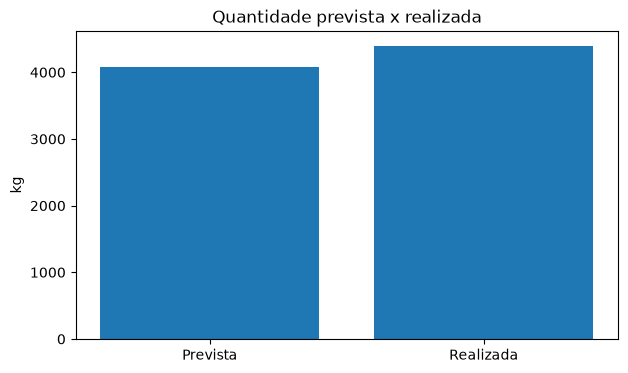

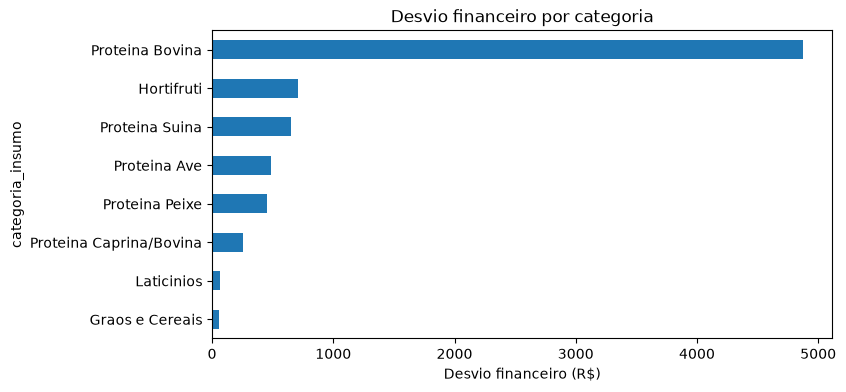

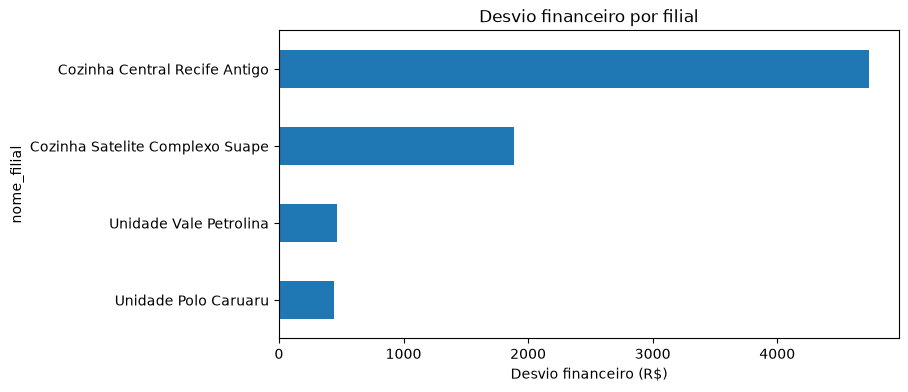

In [7]:
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(["Prevista","Realizada"], [df.qtd_prevista_kg.sum(), df.qtd_real_kg.sum()])
ax.set_ylabel("kg"); ax.set_title("Quantidade prevista x realizada"); plt.show()

fig, ax = plt.subplots(figsize=(8,4))
df.groupby("categoria_insumo")["desvio_cmv_reais"].sum().sort_values().plot(kind="barh", ax=ax)
ax.set_xlabel("Desvio financeiro (R$)"); ax.set_title("Desvio financeiro por categoria"); plt.show()

fig, ax = plt.subplots(figsize=(8,4))
df.groupby("nome_filial")["desvio_cmv_reais"].sum().sort_values().plot(kind="barh", ax=ax)
ax.set_xlabel("Desvio financeiro (R$)"); ax.set_title("Desvio financeiro por filial"); plt.show()

## 7. Limitações e interpretação

- A amostra contém 20 registros e quatro datas de competência; não permite inferência temporal robusta.
- A quantidade de registros por filial e categoria é desigual.
- Correlações entre valores calculados a partir das mesmas grandezas podem refletir dependência matemática, não relação causal.
- A classificação ABC e as fórmulas de fator de correção dependem de confirmação das regras oficiais do CESIC.
- A análise é descritiva/exploratória e não comprova causas dos desvios.